In [1]:
try:
  # This command only in Colab.
  %tensorflow_version 2.x
except Exception:
  pass
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Get project files
!wget https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip

!unzip cats_and_dogs.zip

PATH = 'cats_and_dogs'

train_dir = os.path.join(PATH, 'train')
validation_dir = os.path.join(PATH, 'validation')
test_dir = os.path.join(PATH, 'test')

# Get number of files in each directory. The train and validation directories
# each have the subdirecories "dogs" and "cats".
total_train = sum([len(files) for r, d, files in os.walk(train_dir)])
total_val = sum([len(files) for r, d, files in os.walk(validation_dir)])
total_test = len(os.listdir(test_dir))

# Variables for pre-processing and training.
batch_size = 128
epochs = 15
IMG_HEIGHT = 150
IMG_WIDTH = 150

--2026-11-10 02:32:08--  https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip
Resolving cdn.freecodecamp.org (cdn.freecodecamp.org)... 104.26.3.33, 172.67.70.149, 104.26.2.33
Connecting to cdn.freecodecamp.org (cdn.freecodecamp.org)|104.26.3.33|:443... connected.


HTTP request sent, awaiting response... 

200 OK
Length: 70702765 (67M) [application/zip]
Saving to: ‘cats_and_dogs.zip’

cats_and_dogs.zip     0%[                    ]       0  --.-KB/s               

cats_and_dogs.zip     3%[                    ]   2.58M  12.8MB/s               

cats_and_dogs.zip     8%[>                   ]   5.45M  13.5MB/s               

cats_and_dogs.zip     9%[>                   ]   6.50M  10.5MB/s               

... (41 outputs left out)

  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2296.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2282.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2282.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2057.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2057.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2043.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2043.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2094.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2094.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2080.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2080.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2123.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2123.jpg  
  inflating: cats_and_dogs/validation/dogs/dog.2137.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/dogs/._dog.2137.jpg  
  inflating: cats_and_dogs/validation/dogs

  inflating: cats_and_dogs/validation/cats/cat.2441.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2441.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2327.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2327.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2284.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2284.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2290.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2290.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2247.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2247.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2253.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2253.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2086.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2086.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2092.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/.


  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2421.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2347.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2347.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2353.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2353.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2435.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2435.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2233.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2233.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2227.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2227.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2019.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2019.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2031.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2031.jpg  
  inflating: cats_and_dogs/validation/cat


  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2061.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2075.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2075.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2049.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2049.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2071.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2071.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2065.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2065.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2059.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2059.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2273.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2273.jpg  
  inflating: cats_and_dogs/validation/cats/cat.2267.jpg  
  inflating: __MACOSX/cats_and_dogs/validation/cats/._cat.2267.jpg  
  inflating: cats_and_dogs/validation/cat

In [3]:
# 3
train_image_generator = ImageDataGenerator(rescale=1./255)
validation_image_generator = ImageDataGenerator(rescale=1./255)
test_image_generator = ImageDataGenerator(rescale=1./255)

train_data_gen = train_image_generator.flow_from_directory(batch_size=batch_size,
                                                           directory=train_dir,
                                                           target_size=(IMG_HEIGHT, IMG_WIDTH),
                                                           class_mode='binary')
val_data_gen = validation_image_generator.flow_from_directory(batch_size=batch_size,
                                                              directory=validation_dir,
                                                              target_size=(IMG_HEIGHT, IMG_WIDTH),
                                                              class_mode='binary')
# The test images have no class subfolders, so point at the parent folder,
# select "test" as the only "class" and keep the original file order.
test_data_gen = test_image_generator.flow_from_directory(batch_size=batch_size,
                                                         directory=PATH,
                                                         classes=['test'],
                                                         target_size=(IMG_HEIGHT, IMG_WIDTH),
                                                         class_mode=None,
                                                         shuffle=False)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 50 images belonging to 1 classes.


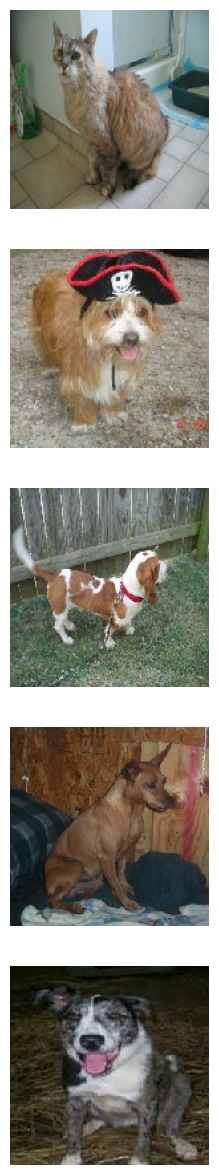

In [4]:
# 4
def plotImages(images_arr, probabilities = False):
    fig, axes = plt.subplots(len(images_arr), 1, figsize=(5,len(images_arr) * 3))
    if probabilities is False:
      for img, ax in zip( images_arr, axes):
          ax.imshow(img)
          ax.axis('off')
    else:
      for img, probability, ax in zip( images_arr, probabilities, axes):
          ax.imshow(img)
          ax.axis('off')
          if probability > 0.5:
              ax.set_title("%.2f" % (probability*100) + "% dog")
          else:
              ax.set_title("%.2f" % ((1-probability)*100) + "% cat")
    plt.show()

sample_training_images, _ = next(train_data_gen)
plotImages(sample_training_images[:5])


In [5]:
# 5
# Random transformations make the small training set look bigger.
train_image_generator = ImageDataGenerator(rescale=1./255,
                                           rotation_range=40,
                                           width_shift_range=0.2,
                                           height_shift_range=0.2,
                                           shear_range=0.2,
                                           zoom_range=0.2,
                                           horizontal_flip=True,
                                           fill_mode='nearest')


Found 2000 images belonging to 2 classes.


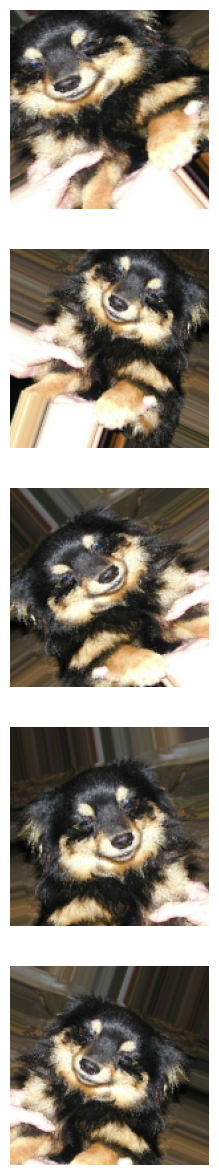

In [6]:
# 6
train_data_gen = train_image_generator.flow_from_directory(batch_size=batch_size,
                                                     directory=train_dir,
                                                     target_size=(IMG_HEIGHT, IMG_WIDTH),
                                                     class_mode='binary')

augmented_images = [train_data_gen[0][0][0] for i in range(5)]

plotImages(augmented_images)

In [7]:
# 7
model = Sequential()
model.add(tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(512, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 8
# 15 epochs are not enough for a network trained from scratch on augmented data.
epochs = 60
history = model.fit(train_data_gen,
                    steps_per_epoch=total_train // batch_size,
                    epochs=epochs,
                    validation_data=val_data_gen,
                    validation_steps=total_val // batch_size,
                    verbose=2)

Epoch 1/60


15/15 - 18s - 1s/step - accuracy: 0.4925 - loss: 0.7046 - val_accuracy: 0.5056 - val_loss: 0.6951


Epoch 2/60


15/15 - 3s - 179ms/step - accuracy: 0.4219 - loss: 0.7046 - val_accuracy: 0.4978 - val_loss: 0.6939


Epoch 3/60


15/15 - 16s - 1s/step - accuracy: 0.5075 - loss: 0.6921 - val_accuracy: 0.4978 - val_loss: 0.6892


... (110 outputs left out)

Epoch 59/60


15/15 - 19s - 1s/step - accuracy: 0.7575 - loss: 0.4931 - val_accuracy: 0.7533 - val_loss: 0.5047


Epoch 60/60


15/15 - 3s - 224ms/step - accuracy: 0.7266 - loss: 0.5420 - val_accuracy: 0.7556 - val_loss: 0.5100


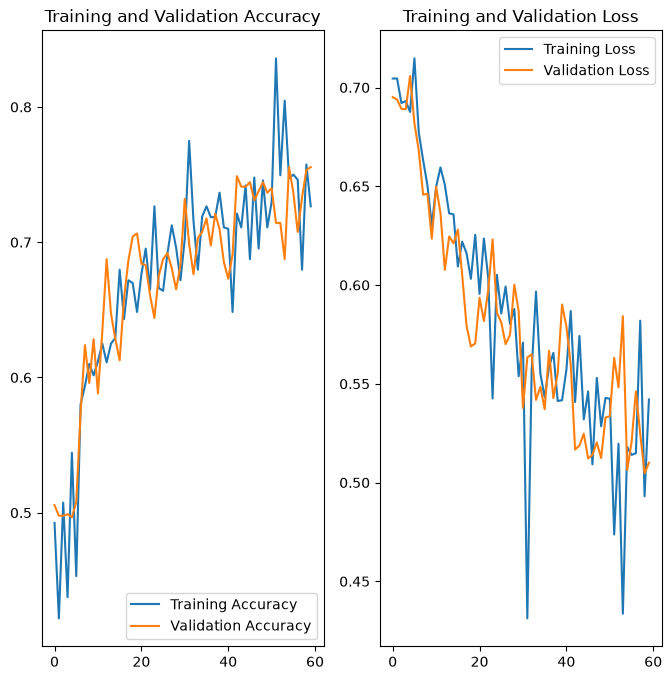

In [9]:
# 9
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step




In [10]:
# 10
probabilities = model.predict(test_data_gen).flatten()
plotImages([test_data_gen[0][i] for i in range(len(probabilities))], probabilities)

In [11]:
# 11
answers =  [1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
            1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
            1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,
            1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 
            0, 0, 0, 0, 0, 0]

correct = 0

for probability, answer in zip(probabilities, answers):
  if round(probability) == answer:
    correct +=1

percentage_identified = (correct / len(answers)) * 100

passed_challenge = percentage_identified >= 63

print(f"Your model correctly identified {round(percentage_identified, 2)}% of the images of cats and dogs.")

if passed_challenge:
  print("You passed the challenge!")
else:
  print("You haven't passed yet. Your model should identify at least 63% of the images. Keep trying. You will get it!")

Your model correctly identified 84.0% of the images of cats and dogs.
You passed the challenge!
